In [1]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

plt.rcParams["figure.figsize"] = (10,6)
plt.rcParams["figure.dpi"] = 120

In [2]:
PROJECT_ROOT = Path(r"D:\Research\Papers\Paper_2")

KITTI_RAW = Path(
    r"D:\Research\Datasets\KITTI"
)

RESULT_DIR = PROJECT_ROOT / "results"

RESULT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print(PROJECT_ROOT)
print(KITTI_RAW)

D:\Research\Papers\Paper_2
D:\Research\Datasets\KITTI


In [3]:
DATE = "2011_09_26"

DRIVE = "2011_09_26_drive_0001_sync"

drive_path = (
    KITTI_RAW
    / DATE
    / DRIVE
)

print(drive_path)

D:\Research\Datasets\KITTI\2011_09_26\2011_09_26_drive_0001_sync


In [4]:
oxts_path = (
    drive_path
    / "oxts"
    / "data"
)

print(oxts_path)

D:\Research\Datasets\KITTI\2011_09_26\2011_09_26_drive_0001_sync\oxts\data


In [5]:
oxts_files = sorted(
    oxts_path.glob("*.txt")
)

print("Total Frames :", len(oxts_files))

Total Frames : 108


In [6]:
sample = np.loadtxt(
    oxts_files[0]
)

print(sample)

[ 4.90150038e+01  8.43429710e+00  1.16430328e+02  3.57520000e-02
  9.03000000e-03 -2.60870698e+00 -6.81144148e+00 -1.12756418e+01
  1.31727167e+01 -1.24752643e-01 -3.29199030e-02 -4.45198146e-01
  4.29573698e-02  1.02098653e+01 -3.40300922e-01 -3.16869154e-01
  1.02091178e+01  9.09517557e-03 -2.31407413e-02 -1.79090345e-02
  8.90180022e-03 -2.24952994e-02 -1.88093309e-02  2.76586334e-02
  1.27279221e-02  4.00000000e+00  1.10000000e+01  6.00000000e+00
  6.00000000e+00  6.00000000e+00]


In [7]:
columns = [

"lat","lon","alt",

"roll","pitch","yaw",

"vn","ve","vf","vl","vu",

"ax","ay","az",

"af","al","au",

"wx","wy","wz",

"wf","wl","wu",

"pos_accuracy",

"vel_accuracy",

"navstat",

"numsats",

"posmode",

"velmode",

"orimode"

]

print(len(columns))

30


In [8]:
records = []

for file in oxts_files:

    records.append(
        np.loadtxt(file)
    )

oxts = pd.DataFrame(
    records,
    columns=columns
)

display(oxts.head())

,lat,lon,alt,roll,pitch,yaw,vn,ve,vf,vl,...,wf,wl,wu,pos_accuracy,vel_accuracy,navstat,numsats,posmode,velmode,orimode
0,49.015004,8.434297,116.430328,0.035752,0.009030,-2.608707,-6.811441,-11.275642,13.172717,-0.124753,...,0.008902,-0.022495,-0.018809,0.027659,0.012728,4.0,11.0,6.0,6.0,6.0
1,49.014997,8.434280,116.432274,0.036453,0.008009,-2.611005,-6.769916,-11.250719,13.129880,-0.129612,...,0.004393,-0.012614,-0.021891,0.027659,0.012728,4.0,11.0,6.0,6.0,6.0
2,49.014991,8.434265,116.435295,0.035908,0.006461,-2.613314,-6.731519,-11.221558,13.084994,-0.140397,...,-0.005684,-0.016039,-0.023276,0.027659,0.012728,4.0,11.0,6.0,6.0,6.0
3,49.014985,8.434249,116.440720,0.035565,0.005031,-2.615904,-6.684933,-11.198743,13.041455,-0.144497,...,-0.005634,-0.013817,-0.024773,0.027659,0.012728,4.0,11.0,6.0,6.0,6.0
4,49.014979,8.434233,116.447853,0.034299,0.006470,-2.618804,-6.634209,-11.175295,12.995313,-0.148616,...,-0.009492,0.011586,-0.026827,0.027659,0.012728,4.0,11.0,6.0,6.0,6.0


In [9]:
print("="*60)

print("Frames :", len(oxts))

print("Columns :", len(oxts.columns))

print("="*60)

display(oxts.describe())

Frames : 108
Columns : 30


,lat,lon,alt,roll,pitch,yaw,vn,ve,vf,vl,...,wf,wl,wu,pos_accuracy,vel_accuracy,navstat,numsats,posmode,velmode,orimode
count,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000,...,1.080000e+02,108.000000,108.000000,108.000000,108.000000,108.0,108.000000,108.0,108.0,108.0
mean,49.014762,8.433552,116.464296,0.029971,0.012445,-2.718472,-4.139566,-8.796198,9.733675,-0.072965,...,9.159165e-07,0.000626,-0.013340,0.027425,0.012171,4.0,9.842593,6.0,6.0,6.0
std,0.000119,0.000399,0.017301,0.005170,0.003655,0.044789,1.373708,1.979072,2.357728,0.047267,...,1.136685e-02,0.009207,0.013656,0.000619,0.000585,0.0,1.305359,0.0,0.0,0.0
min,49.014596,8.432972,116.426804,0.019599,0.005031,-2.754572,-6.811441,-11.275642,4.611723,-0.157731,...,-4.124870e-02,-0.022495,-0.040925,0.026907,0.011314,4.0,7.000000,6.0,6.0,6.0
25%,49.014658,8.433194,116.452316,0.026415,0.009947,-2.751804,-5.158587,-10.385950,7.963623,-0.104715,...,-7.241098e-03,-0.004362,-0.024349,0.026907,0.011314,4.0,9.000000,6.0,6.0,6.0
50%,49.014744,8.433510,116.466743,0.030645,0.012657,-2.746841,-4.016737,-9.507683,10.321101,-0.076025,...,7.724918e-04,-0.000164,-0.011143,0.026907,0.012042,4.0,11.000000,6.0,6.0,6.0
75%,49.014857,8.433890,116.479881,0.033122,0.013941,-2.690648,-3.053240,-7.355096,11.596100,-0.028728,...,6.308839e-03,0.005721,0.000941,0.027659,0.012728,4.0,11.000000,6.0,6.0,6.0
max,49.015004,8.434297,116.490036,0.043410,0.021188,-2.608707,-1.803772,-4.244788,13.172717,0.016331,...,4.485511e-02,0.031626,0.005523,0.028425,0.012728,4.0,11.000000,6.0,6.0,6.0


In [10]:
missing = oxts.isnull().sum()

display(missing)

lat             0
lon             0
alt             0
roll            0
pitch           0
yaw             0
vn              0
ve              0
vf              0
vl              0
vu              0
ax              0
ay              0
az              0
af              0
al              0
au              0
wx              0
wy              0
wz              0
wf              0
wl              0
wu              0
pos_accuracy    0
vel_accuracy    0
navstat         0
numsats         0
posmode         0
velmode         0
orimode         0
dtype: int64

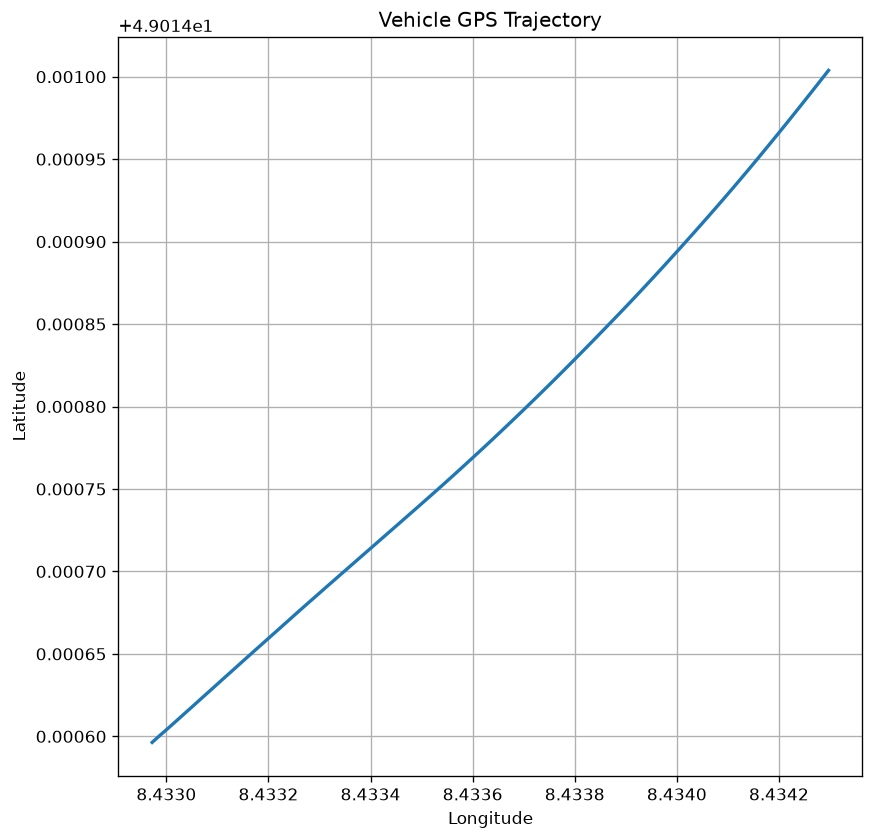

In [11]:
plt.figure(figsize=(8,8))

plt.plot(

    oxts["lon"],

    oxts["lat"],

    linewidth=2

)

plt.title("Vehicle GPS Trajectory")

plt.xlabel("Longitude")

plt.ylabel("Latitude")

plt.grid(True)

plt.show()

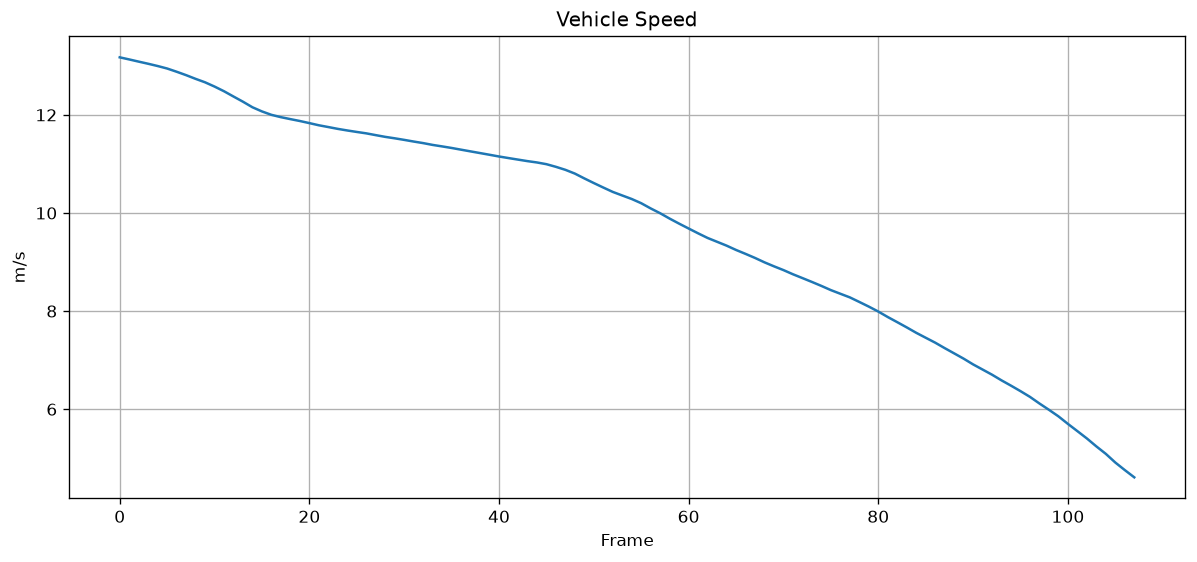

In [12]:
speed = np.sqrt(

      oxts["vn"]**2

    + oxts["ve"]**2

)

plt.figure(figsize=(12,5))

plt.plot(speed)

plt.title("Vehicle Speed")

plt.xlabel("Frame")

plt.ylabel("m/s")

plt.grid(True)

plt.show()

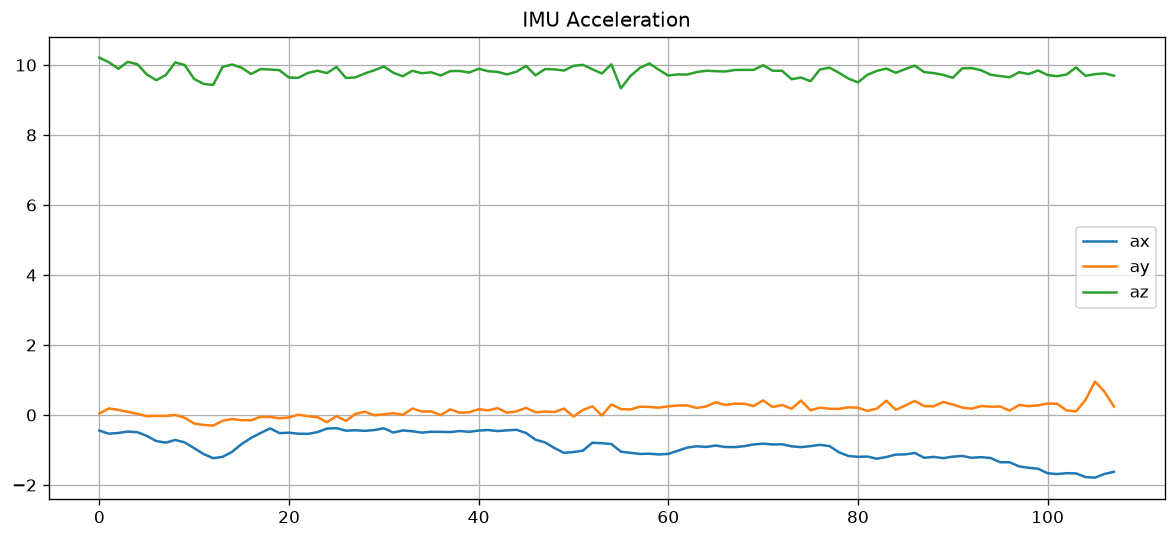

In [13]:
plt.figure(figsize=(12,5))

plt.plot(
    oxts["ax"],
    label="ax"
)

plt.plot(
    oxts["ay"],
    label="ay"
)

plt.plot(
    oxts["az"],
    label="az"
)

plt.legend()

plt.grid(True)

plt.title("IMU Acceleration")

plt.show()

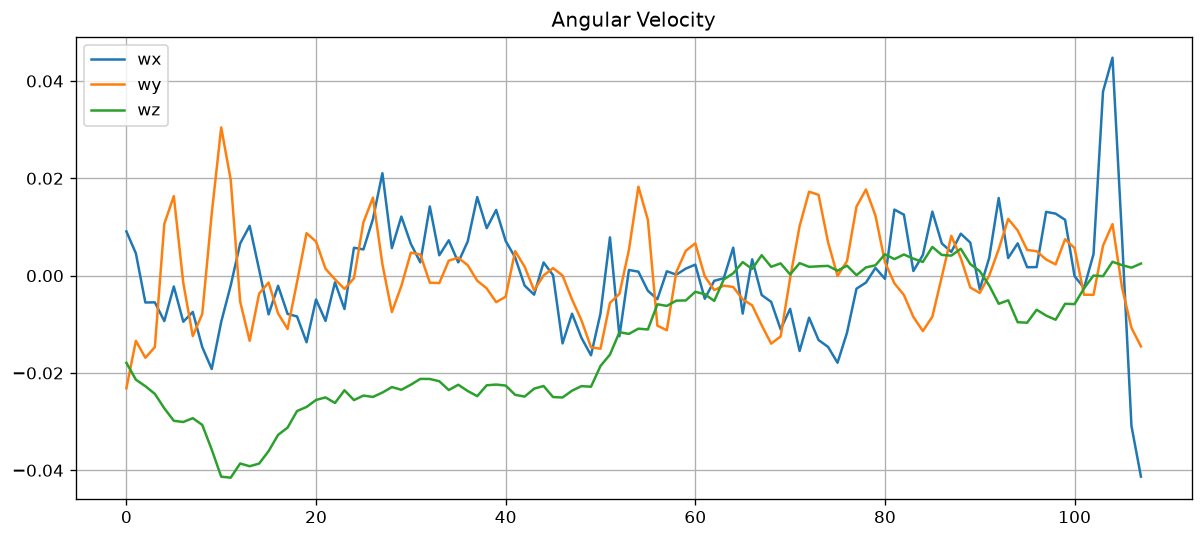

In [14]:
plt.figure(figsize=(12,5))

plt.plot(
    oxts["wx"],
    label="wx"
)

plt.plot(
    oxts["wy"],
    label="wy"
)

plt.plot(
    oxts["wz"],
    label="wz"
)

plt.legend()

plt.grid(True)

plt.title("Angular Velocity")

plt.show()

In [15]:
oxts.to_csv(

    RESULT_DIR /

    f"oxts_dataframe_{DRIVE}.csv",

    index=False

)

print("Saved :", f"oxts_dataframe_{DRIVE}.csv")

print("Saved OXTS DataFrame")

Saved : oxts_dataframe_2011_09_26_drive_0001_sync.csv
Saved OXTS DataFrame


In [16]:
# ============================================================
# GPS Position Stability (Improved - Haversine Distance)
# ============================================================

EARTH_RADIUS = 6371000.0

lat = np.radians(oxts["lat"].values)
lon = np.radians(oxts["lon"].values)

dlat = np.diff(lat)
dlon = np.diff(lon)

a = (
    np.sin(dlat / 2) ** 2
    + np.cos(lat[:-1])
    * np.cos(lat[1:])
    * np.sin(dlon / 2) ** 2
)

c = 2 * np.arctan2(
    np.sqrt(a),
    np.sqrt(1 - a)
)

gps_distance = EARTH_RADIUS * c

gps_distance = np.insert(
    gps_distance,
    0,
    gps_distance[0]
)

oxts["GPS Distance (m)"] = gps_distance

# ------------------------------------------------------------
# Improved GPS Position Stability
# ------------------------------------------------------------

mean_distance = gps_distance.mean()

oxts["GPS Position Stability"] = np.exp(
    -gps_distance / mean_distance
)

display(
    oxts[
        [
            "GPS Distance (m)",
            "GPS Position Stability"
        ]
    ].head()
)

,GPS Distance (m),GPS Position Stability
0,1.440993,0.237597
1,1.440993,0.237597
2,1.305492,0.271977
3,1.300312,0.273386
4,1.425824,0.241219


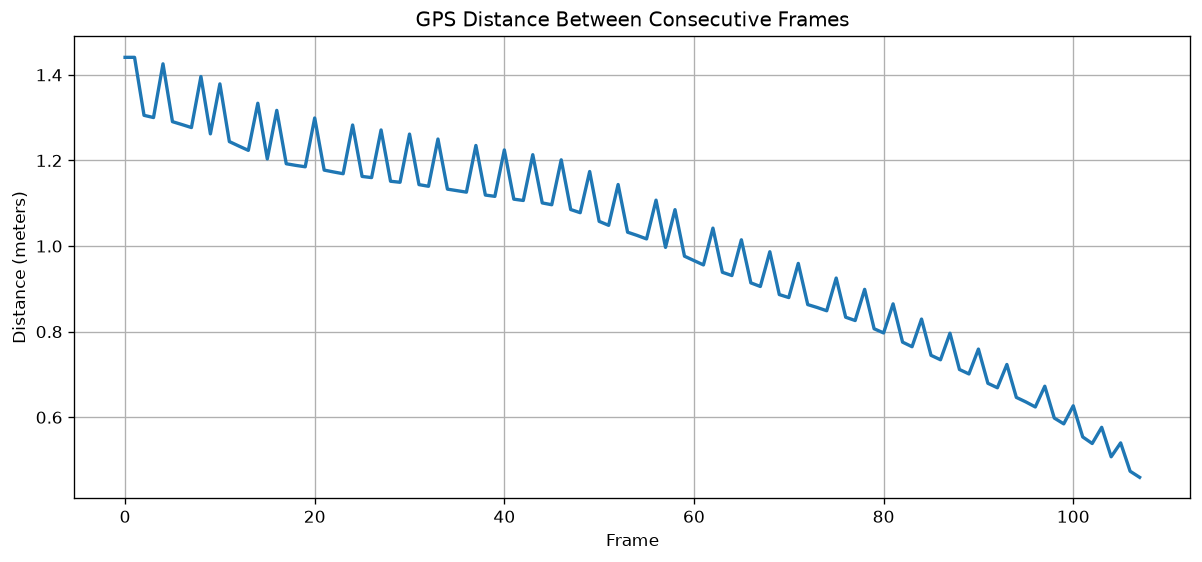

In [17]:
plt.figure(figsize=(12,5))

plt.plot(
    oxts["GPS Distance (m)"],
    linewidth=2
)

plt.title("GPS Distance Between Consecutive Frames")

plt.xlabel("Frame")

plt.ylabel("Distance (meters)")

plt.grid(True)

plt.show()

In [18]:
display(
    oxts[
        [
            "GPS Distance (m)",
            "GPS Position Stability"
        ]
    ].describe()
)

,GPS Distance (m),GPS Position Stability
count,108.000000,108.000000
mean,1.002654,0.379559
std,0.248549,0.098373
min,0.459667,0.237597
25%,0.821242,0.305332
50%,1.053127,0.349823
75%,1.189504,0.440857
max,1.440993,0.632262


In [19]:
# ============================================================
# GPS Velocity Stability
# ============================================================

speed = np.sqrt(

    oxts["vn"]**2 +

    oxts["ve"]**2 +

    oxts["vu"]**2

)

velocity_change = np.abs(

    np.diff(speed)

)

velocity_change = np.insert(

    velocity_change,

    0,

    velocity_change[0]

)

gps_velocity_stability = 1 / (

    1 + velocity_change

)

oxts["GPS Velocity Stability"] = gps_velocity_stability

display(

oxts[[

"GPS Velocity Stability"

]].head()

)

,GPS Velocity Stability
0,0.958935
1,0.958935
2,0.957166
3,0.958347
4,0.956050


In [20]:
# ============================================================
# GPS Heading Stability
# ============================================================

heading_change = np.abs(

    np.diff(oxts["yaw"])

)

heading_change = np.insert(

    heading_change,

    0,

    heading_change[0]

)

gps_heading_stability = 1 / (

    1 + heading_change

)

oxts["GPS Heading Stability"] = gps_heading_stability

display(

oxts[[

"GPS Heading Stability"

]].head()

)

,GPS Heading Stability
0,0.997707
1,0.997707
2,0.997696
3,0.997417
4,0.997108


In [21]:
# ============================================================
# Satellite Quality
# ============================================================

sat_quality = (

    oxts["numsats"]

    /

    oxts["numsats"].max()

)

oxts["Satellite Quality"] = sat_quality

display(

oxts[[

"numsats",

"Satellite Quality"

]].head()

)

,numsats,Satellite Quality
0,11.0,1.0
1,11.0,1.0
2,11.0,1.0
3,11.0,1.0
4,11.0,1.0


In [22]:
# ============================================================
# Position Accuracy Score
# ============================================================

pos_accuracy = oxts["pos_accuracy"]

position_score = 1 - (

    (pos_accuracy - pos_accuracy.min())

    /

    (pos_accuracy.max() -

     pos_accuracy.min())

)

oxts["Position Accuracy Score"] = position_score

display(

oxts[[

"Position Accuracy Score"

]].head()

)

,Position Accuracy Score
0,0.505047
1,0.505047
2,0.505047
3,0.505047
4,0.505047


In [23]:
# ============================================================
# Velocity Accuracy Score (Improved)
# ============================================================

vel_accuracy = oxts["vel_accuracy"]

# Robust statistics
median = vel_accuracy.median()

mad = np.median(
    np.abs(vel_accuracy - median)
)

# Prevent division by zero
mad = max(mad, 1e-6)

# Robust exponential confidence
velocity_score = np.exp(
    -np.abs(vel_accuracy - median)
    /
    (3 * mad)
)

oxts["Velocity Accuracy Score"] = velocity_score

display(
    oxts[
        [
            "vel_accuracy",
            "Velocity Accuracy Score"
        ]
    ].head()
)

print("="*60)
print("Average Velocity Accuracy Score :",
      round(oxts["Velocity Accuracy Score"].mean(),3))
print("="*60)

,vel_accuracy,Velocity Accuracy Score
0,0.012728,0.716531
1,0.012728,0.716531
2,0.012728,0.716531
3,0.012728,0.716531
4,0.012728,0.716531


Average Velocity Accuracy Score : 0.792


In [24]:
# ============================================================
# IMU Motion Smoothness
# ============================================================

acceleration = np.sqrt(

    oxts["ax"]**2 +

    oxts["ay"]**2 +

    oxts["az"]**2

)

motion_change = np.abs(

    np.diff(acceleration)

)

motion_change = np.insert(

    motion_change,

    0,

    motion_change[0]

)

motion_smoothness = 1 / (

    1 + motion_change

)

oxts["Motion Smoothness"] = motion_smoothness

display(

oxts[[

"Motion Smoothness"

]].head()

)

,Motion Smoothness
0,0.888550
1,0.888550
2,0.841668
3,0.835807
4,0.936416


In [25]:
# ============================================================
# IMU Angular Stability
# ============================================================

angular_rate = np.sqrt(

    oxts["wx"]**2 +

    oxts["wy"]**2 +

    oxts["wz"]**2

)

angular_change = np.abs(

    np.diff(angular_rate)

)

angular_change = np.insert(

    angular_change,

    0,

    angular_change[0]

)

angular_stability = 1 / (

    1 + angular_change

)

oxts["Angular Stability"] = angular_stability

display(

oxts[[

"Angular Stability"

]].head()

)

,Angular Stability
0,0.995026
1,0.995026
2,0.996825
3,0.999911
4,0.998203


In [26]:
gps_summary = pd.DataFrame({

"Metric":[

"GPS Position Stability",

"GPS Velocity Stability",

"GPS Heading Stability",

"Satellite Quality",

"Position Accuracy",

"Velocity Accuracy",

"Motion Smoothness",

"Angular Stability"

],

"Average":[

oxts["GPS Position Stability"].mean(),

oxts["GPS Velocity Stability"].mean(),

oxts["GPS Heading Stability"].mean(),

oxts["Satellite Quality"].mean(),

oxts["Position Accuracy Score"].mean(),

oxts["Velocity Accuracy Score"].mean(),

oxts["Motion Smoothness"].mean(),

oxts["Angular Stability"].mean()

]

})

display(gps_summary)


,Metric,Average
0,GPS Position Stability,0.379559
1,GPS Velocity Stability,0.927272
2,GPS Heading Stability,0.998483
3,Satellite Quality,0.894781
4,Position Accuracy,0.658622
5,Velocity Accuracy,0.791561
6,Motion Smoothness,0.898902
7,Angular Stability,0.995687


In [27]:
# ============================================================
# Save Results
# ============================================================

oxts.to_csv(

    RESULT_DIR /

    f"sensor_quality_metrics_{DRIVE}.csv",

    index=False

)

gps_summary.to_csv(

    RESULT_DIR /

    f"sensor_quality_summary_{DRIVE}.csv",

    index=False

)

print("=" * 80)

print("NOTEBOOK 07 COMPLETED SUCCESSFULLY")

print("=" * 80)

print()

print("Drive :", DRIVE)

print("Frames Processed :", len(oxts))

print()

print("Generated Files")

print("----------------------------")

print(f"oxts_dataframe_{DRIVE}.csv")

print(f"sensor_quality_metrics_{DRIVE}.csv")

print(f"sensor_quality_summary_{DRIVE}.csv")

print()

print("READY FOR NOTEBOOK 08")

print("=" * 80)

NOTEBOOK 07 COMPLETED SUCCESSFULLY

Drive : 2011_09_26_drive_0001_sync
Frames Processed : 108

Generated Files
----------------------------
oxts_dataframe_2011_09_26_drive_0001_sync.csv
sensor_quality_metrics_2011_09_26_drive_0001_sync.csv
sensor_quality_summary_2011_09_26_drive_0001_sync.csv

READY FOR NOTEBOOK 08
